## Setup

In [15]:
import pandas as pd  # tables of data
import matplotlib.pyplot as plt  # charts

data_path = "/content/drive/My Drive/neet_data.csv"  # where the cleaned data lives on Drive
fig5_path = "/content/drive/My Drive/fig5_neet_total_by_sex_2013_2026.png"  # where the line chart is saved on Drive

## Mount Google Drive

In [16]:
from google.colab import drive  # Colab's Google Drive tool
drive.mount("/content/drive")  # connect Google Drive

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## Load the data

In [17]:
df = pd.read_csv(data_path)  # load the cleaned data into a table

## Table 6: NEET rate by year and sex, ages 16 to 24, 2013 to 2026

In [18]:
def wmean(data, var):  # weighted mean of one variable
    d = data.dropna(subset=[var])  # leave out people with a missing value
    return (d[var] * d["asecwt"]).sum() / d["asecwt"].sum()  # sum of value x weight, divided by sum of weights

years = list(range(2013, 2027))  # the years in the table, 2013 to 2026
sample = df[df["year"].isin(years) & ((df["age16_19"] == 1) | (df["age20_24"] == 1))].copy()  # keep 2013 to 2026 and ages 16 to 24

label_for = df.drop_duplicates("female").set_index("female")["sex_label"]  # sex_label for each value of female
columns = {"Total": None, label_for[0]: 0, label_for[1]: 1}  # column names and the female value each one uses: Total, Male, Female

left_out = sample["neet"].isna().groupby(sample["year"]).sum()  # people left out in each year because neet is missing
known = sample.dropna(subset=["neet"])  # keep only people whose neet is known

rate = {}  # weighted NEET rate, one row per year
people = {}  # unweighted respondents, same layout
for year in years:  # loop over the years
    year_data = known[known["year"] == year]  # people in this year
    rate[year] = {}  # start this row of the table
    people[year] = {}  # start this row of the counts
    for column_name, female_value in columns.items():  # loop over Total, Male, Female
        group = year_data if female_value is None else year_data[year_data["female"] == female_value]  # everyone, or one sex
        rate[year][column_name] = wmean(group, "neet") * 100  # weighted percent NEET
        people[year][column_name] = len(group)  # unweighted respondents in this cell

table = pd.DataFrame(rate).T  # dictionary -> table, one row per year
people = pd.DataFrame(people).T  # same layout for the counts

print("People left out because neet is missing, by year (unweighted):")  # left-out title
print(left_out.to_string())  # one number per year
print()  # empty line
print("Table 6. NEET rate, % of people aged 16 to 24 with a known neet (weighted with asecwt).")  # table title
print(table.to_string(float_format="{:.1f}".format))  # table, 1 decimal
print()  # empty line
print("Check: every year from 2013 to 2026 is in the table:", list(table.index) == years)  # True or False
print("Check: every year has a value in all three columns:", bool(table.notna().all().all()))  # True or False
print()  # empty line
print("Unweighted number of respondents in each cell (neet not missing).")  # counts title
print(people.to_string())  # counts, same layout

People left out because neet is missing, by year (unweighted):
year
2013    111
2014    130
2015    135
2016    111
2017     90
2018    100
2019    107
2020     92
2021     94
2022     92
2023     83
2024     70
2025     75
2026     61

Table. NEET rate, % of people aged 16 to 24 with a known neet (weighted with asecwt).
      Total  Male  Female
2013   14.4  13.9    14.8
2014   13.9  13.3    14.4
2015   13.7  12.8    14.7
2016   13.1  12.7    13.6
2017   11.2  10.7    11.7
2018   11.4  10.9    11.8
2019   10.9  10.5    11.4
2020   12.5  12.7    12.3
2021   13.5  13.8    13.3
2022   12.7  12.2    13.3
2023   11.1  10.5    11.7
2024   12.1  11.6    12.5
2025   11.8  11.9    11.7
2026   11.5  11.2    11.8

Check: every year from 2013 to 2026 is in the table: True
Check: every year has a value in all three columns: True

Unweighted number of respondents in each cell (neet not missing).
      Total   Male  Female
2013  24160  12092   12068
2014  23429  11811   11618
2015  23225  11746   11

**What one cell means.** Take the row 2019 and the column "Female". Among women aged 16 to 24 in the 2019 survey whose NEET status is known, the cell is the percent who were NEET: not employed and not in school. The column "Male" is the same percent for men, and the column "Total" is the same percent for men and women together. People whose NEET status could not be determined are left out, not counted as zero. People are counted by how many people in the country they represent (`asecwt`), so each number describes the population, not just the people surveyed. A cell of 10.0 means 10 out of every 100 such people were NEET. The count table under the table shows how many survey respondents sit behind each cell.

## Figure 5: NEET rate by year and sex, ages 16 to 24, 2013 to 2026

Table. NEET rate, % of people aged 16 to 24 with a known neet (weighted with asecwt). The chart shows this table.
      Total  Male  Female
2013   14.4  13.9    14.8
2014   13.9  13.3    14.4
2015   13.7  12.8    14.7
2016   13.1  12.7    13.6
2017   11.2  10.7    11.7
2018   11.4  10.9    11.8
2019   10.9  10.5    11.4
2020   12.5  12.7    12.3
2021   13.5  13.8    13.3
2022   12.7  12.2    13.3
2023   11.1  10.5    11.7
2024   12.1  11.6    12.5
2025   11.8  11.9    11.7
2026   11.5  11.2    11.8


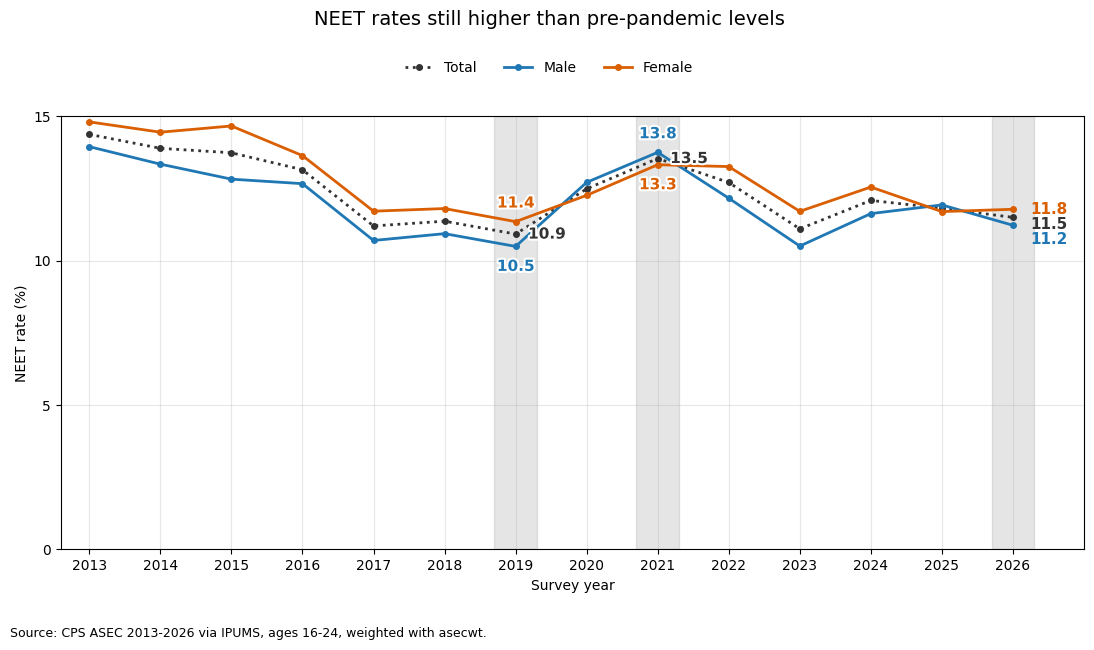

In [22]:
chart_title = "NEET rates still higher than pre-pandemic levels"  # chart title: replace this text with your own sentence

print("Table 6. NEET rate, % of people aged 16 to 24 with a known neet (weighted with asecwt). Figure 5 shows this table.")  # table title
print(table.to_string(float_format="{:.1f}".format))  # table, 1 decimal

line_styles = {"Total": ":", table.columns[1]: "-", table.columns[2]: "-"}  # Total dotted, Male and Female solid
line_colors = {"Total": "#333333", table.columns[1]: "#1f77b4", table.columns[2]: "#d95f02"}  # a different color for each line
ymax = int(table.max().max() / 5) * 5 + 5  # round number just above the highest value in the table
last_year = table.index.max()  # the last year, 2026

fig, ax = plt.subplots(figsize=(11, 6.5))  # one chart
for year in [2019, 2021, last_year]:  # the three highlighted years
    ax.axvspan(year - 0.3, year + 0.3, color="gray", alpha=0.2, zorder=0)  # translucent grey column behind the lines
for column in table.columns:  # one line for each column: Total, Male, Female
    ax.plot(table.index, table[column], linestyle=line_styles[column], color=line_colors[column], marker="o", markersize=4, linewidth=2, label=column)  # line with a small marker on each point

end_values = table.loc[last_year].sort_values(ascending=False)  # last-year values, highest first
min_gap = ymax * 0.035  # smallest vertical space between two end labels
label_y = {}  # where each end label is written
previous = None  # height of the label above
for column, value in end_values.items():  # loop from the highest line to the lowest
    y = value if previous is None else min(value, previous - min_gap)  # move a label down if it would overlap the one above
    label_y[column] = y  # remember where it goes
    previous = y  # next label must sit below this one
for column, value in end_values.items():  # write the end labels
    ax.text(last_year + 0.25, label_y[column], f"{value:.1f}", color=line_colors[column], va="center", ha="left", fontsize=11, fontweight="bold")  # value of the last year at the end of the line

import matplotlib.patheffects as pe  # text outlines
total_name = table.columns[0]  # the Total column
sex_names = list(table.columns[1:])  # the Male and Female columns
for year in [2019, 2021]:  # years to label in the middle of the chart
    values = table.loc[year]  # the three values for this year
    top = values[sex_names].idxmax()  # the higher of Male and Female
    bottom = [name for name in sex_names if name != top][0]  # the other one, the lower
    outline = [pe.withStroke(linewidth=3, foreground="white")]  # thin white outline so the number is easy to read without hiding the lines
    ax.annotate(f"{values[top]:.1f}", (year, values[top]), xytext=(0, 8), textcoords="offset points", ha="center", va="bottom", color=line_colors[top], fontsize=11, fontweight="bold", path_effects=outline)  # higher line: value above the point
    ax.annotate(f"{values[bottom]:.1f}", (year, values[bottom]), xytext=(0, -9), textcoords="offset points", ha="center", va="top", color=line_colors[bottom], fontsize=11, fontweight="bold", path_effects=outline)  # lower line: value below the point
    ax.annotate(f"{values[total_name]:.1f}", (year, values[total_name]), xytext=(9, 0), textcoords="offset points", ha="left", va="center", color=line_colors[total_name], fontsize=11, fontweight="bold", path_effects=outline)  # Total line: value to the right of the point

ax.set_xticks(list(table.index))  # a tick for every year
ax.set_xlim(table.index.min() - 0.4, last_year + 1.0)  # room at the right for the end labels
ax.set_xlabel("Survey year")  # x-axis label
ax.set_ylabel("NEET rate (%)")  # y-axis label
ax.set_ylim(0, ymax)  # y-axis starts at 0
ax.set_yticks(range(0, ymax + 1, 5))  # y ticks every 5, starting at 0
ax.grid(True, alpha=0.3)  # light grid

handles, labels = ax.get_legend_handles_labels()  # the three lines
fig.legend(handles, labels, loc="upper center", bbox_to_anchor=(0.5, 0.92), ncol=3, frameon=False)  # one legend
fig.suptitle(chart_title, fontsize=14, y=0.98)  # chart title
fig.text(0.01, 0.99, "Figure 5", fontsize=12, fontweight="bold", va="top")  # figure label, top left
fig.tight_layout(rect=[0, 0.06, 1, 0.9])  # leave room for the title, legend and note
fig.text(0.01, 0.015, "Source: CPS ASEC 2013-2026 via IPUMS, ages 16-24, weighted with asecwt.", fontsize=9)  # source note
fig.savefig(fig5_path, dpi=200, bbox_inches="tight")  # save to Drive before showing
plt.show()  # show the chart

## Write-up (50-100 words)

Question:
Finding: